# **Run 9: pretrained CNN, RegNetY-32GF (SWAG), linear probe then fine-tuning (target: 99%+ with a real CNN)**
- **Why a new run:** the assignment is about **CNNs** (convolution and pooling layers). Run 8 reached 99.31%, but ViT-L is a
  transformer, not a CNN. This run applies the same LP-FT recipe to a **convolutional** network pretrained on the same
  SWAG data (3.6B images): torchvision's **RegNetY-32GF** (145M parameters, only convolutions, BatchNorm, squeeze-and-
  excitation and pooling, no attention).
- **Methodology fix** (the caveat at the end of EXPERIMENTS.md): 5,000 training images are held out as a **validation
  split**. The epoch to keep is chosen on validation accuracy only; the test set is used to report the result. Test
  accuracy is still printed every epoch so it can be plotted, but it is never used for a decision.

Differences from Run 8, and why:
- **BatchNorm.** During the linear probe the backbone stays in eval mode, so its BatchNorm statistics are not changed
  while the head is still random. No gradient accumulation (it would change the BatchNorm batch statistics).
- **Layer-wise LR decay per stage** (stem, 4 stages, head = 6 levels, decay 0.5) instead of per transformer block.
- **Base LR 1e-4** instead of 2e-5: convolutional networks with BatchNorm tolerate a larger fine-tuning LR than ViT.

In [1]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less fragmentation; must be set before torch
import gc, copy, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True       # fixed 224x224 inputs: pick the fastest conv algorithms
print(device, torch.__version__, torch.cuda.get_device_name(0) if device == "cuda" else "")
free, total = torch.cuda.mem_get_info()
print(f"GPU memory free: {free / 2**30:.1f} / {total / 2**30:.1f} GiB")
if free < 10 * 2**30:
    print("WARNING: less than 10 GiB free. Close other notebook kernels / GPU apps, or training may run out of memory.")

cuda 2.14.0+cu130 NVIDIA GeForce RTX 5080
GPU memory free: 14.6 / 15.9 GiB


# **Data (45,000 train / 5,000 validation / 10,000 test)**

In [2]:
IMG_SIZE = 224
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
DATA_PATH = "../dataset"

# light augmentation at 32x32 on the CPU; upscaling + normalization on the GPU
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
full_train = datasets.CIFAR10(root=DATA_PATH, train=True, download=True, transform=train_transform)
full_train_plain = datasets.CIFAR10(root=DATA_PATH, train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.CIFAR10(root=DATA_PATH, train=False, download=True, transform=transforms.ToTensor())

# hold out 5,000 training images for validation (same split in Runs 9, 10 and 11)
VAL_SIZE = 5000
perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(0))
val_idx, train_idx = perm[:VAL_SIZE].tolist(), perm[VAL_SIZE:].tolist()
train_dataset = Subset(full_train, train_idx)           # augmented
val_dataset = Subset(full_train_plain, val_idx)          # not augmented, like the test set

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4,
                          pin_memory=True, persistent_workers=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=4,
                        pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=4,
                         pin_memory=True, persistent_workers=True)
classes = full_train.classes

def to_model_input(images):
    """32x32 [0,1] batch on GPU -> 224x224 ImageNet-normalized batch"""
    images = F.interpolate(images, size=IMG_SIZE, mode="bicubic", align_corners=False).clamp(0, 1)
    return ((images - IMAGENET_MEAN) / IMAGENET_STD).contiguous(memory_format=torch.channels_last)

print(f"Train length: {len(train_dataset)}\nValidation length: {len(val_dataset)}\nTest length: {len(test_dataset)}")
print(f"Classes: {classes}")

Train length: 45000
Validation length: 5000
Test length: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Model: pretrained RegNetY-32GF SWAG (a CNN) with a new 10-class head**

In [3]:
from torchvision.models import regnet_y_32gf, RegNet_Y_32GF_Weights

model = regnet_y_32gf(weights=RegNet_Y_32GF_Weights.IMAGENET1K_SWAG_LINEAR_V1)    # downloads ~580MB once
model.fc = nn.Linear(model.fc.in_features, 10)                                     # 3712 -> 10 classes
nn.init.zeros_(model.fc.weight)
nn.init.zeros_(model.fc.bias)
model = model.to(device).to(memory_format=torch.channels_last)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M")
n_conv = sum(isinstance(m, nn.Conv2d) for m in model.modules())
n_attn = sum(isinstance(m, nn.MultiheadAttention) for m in model.modules())
print(f"Conv2d layers: {n_conv} | attention layers: {n_attn}")
print(model.stem)
print(model.trunk_output.block1[0])          # first block: 1x1 conv -> grouped 3x3 conv -> squeeze-excitation -> 1x1 conv

Downloading: "https://download.pytorch.org/models/regnet_y_32gf_lc_swag-e1583746.pth" to C:\Users\GAMING/.cache\torch\hub\checkpoints\regnet_y_32gf_lc_swag-e1583746.pth


100%|██████████| 554M/554M [01:33<00:00, 6.23MB/s] 


Parameters: 141M
Conv2d layers: 105 | attention layers: 0
SimpleStemIN(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
)
ResBottleneckBlock(
  (proj): Conv2dNormActivation(
    (0): Conv2d(32, 232, kernel_size=(1, 1), stride=(2, 2), bias=False)
    (1): BatchNorm2d(232, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (f): BottleneckTransform(
    (a): Conv2dNormActivation(
      (0): Conv2d(32, 232, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(232, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (b): Conv2dNormActivation(
      (0): Conv2d(232, 232, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(232, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stat

# **Training and Evaluation**

In [4]:
AMP_DTYPE = torch.bfloat16
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def train_one_epoch(model, loader, optimizer, scheduler, params, backbone_frozen=False):
    model.train(not backbone_frozen)       # frozen backbone: keep BatchNorm statistics as pretrained
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = to_model_input(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            outputs = model(images)
            loss = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, tta=True, return_logits=False):
    model.eval()
    total_loss, correct, total, all_logits, all_labels = 0, 0, 0, [], []
    with torch.no_grad():
        for images, labels in loader:
            images = to_model_input(images.to(device, non_blocking=True))
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
                outputs = model(images)
                if tta:                                 # average with horizontally flipped images
                    outputs = (outputs + model(torch.flip(images, dims=[3]))) / 2
            outputs = outputs.float()
            total_loss += criterion(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
            if return_logits:
                all_logits.append(outputs.cpu()); all_labels.append(labels.cpu())
    if return_logits:
        return total_loss / total, correct / total, torch.cat(all_logits), torch.cat(all_labels)
    return total_loss / total, correct / total

history = {"stage": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "test_loss": [], "test_acc": []}

def log_epoch(stage, epoch, epochs, tr_loss, tr_acc, va_loss, va_acc, te_loss, te_acc, seconds):
    for k, v in zip(history, (stage, tr_loss, tr_acc, va_loss, va_acc, te_loss, te_acc)):
        history[k].append(v)
    print(f"[{stage}] Epoch {epoch}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} | val acc {va_acc:.4f} | test loss {te_loss:.4f} | test acc {te_acc:.4f} | {seconds / 60:.1f} min")

# **Stage 1: linear probe (backbone frozen, train only the head)**

In [5]:
LP_EPOCHS = 1
for p in model.parameters():
    p.requires_grad = False
head_params = list(model.fc.parameters())
for p in head_params:
    p.requires_grad = True

optimizer = optim.AdamW(head_params, lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-3, epochs=LP_EPOCHS,
                                          steps_per_epoch=len(train_loader), pct_start=0.1)
for epoch in range(LP_EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scheduler, head_params, backbone_frozen=True)
    va_loss, va_acc = evaluate(model, val_loader)
    te_loss, te_acc = evaluate(model, test_loader)
    log_epoch("probe", epoch + 1, LP_EPOCHS, tr_loss, tr_acc, va_loss, va_acc, te_loss, te_acc, time.time() - t0)

Training:   0%|          | 0/1406 [00:14<?, ?it/s]

[probe] Epoch 1/1 | train loss 0.8562 | train acc 0.8930 | val loss 0.6540 | val acc 0.9574 | test loss 0.6740 | test acc 0.9467 | 5.1 min


# **Stage 2: fine-tune everything with stage-wise LR decay**

In [6]:
FT_EPOCHS = 5
BASE_LR = 1e-4          # LR of the head
LAYER_DECAY = 0.5       # each stage below gets 0.5x the LR of the stage above

del optimizer, scheduler                                   # free stage-1 state before the big optimizer is created
gc.collect()
torch.cuda.empty_cache()

for p in model.parameters():
    p.requires_grad = True

TOP = 5                                                    # stem=0, block1..block4=1..4, head=5
def layer_id(name):
    if name.startswith("stem"):
        return 0
    if name.startswith("trunk_output.block"):
        return int(name.split(".")[1].replace("block", ""))
    return TOP

groups = {}
for name, p in model.named_parameters():
    lid = layer_id(name)
    no_wd = p.ndim == 1                                    # BatchNorm weights/biases and all biases: no weight decay
    key = (lid, no_wd)
    if key not in groups:
        groups[key] = {"params": [], "lr": BASE_LR * LAYER_DECAY ** (TOP - lid),
                       "weight_decay": 0.0 if no_wd else 0.05}
    groups[key]["params"].append(p)
param_groups = list(groups.values())
for lid in range(TOP + 1):
    print(f"level {lid}: lr {BASE_LR * LAYER_DECAY ** (TOP - lid):.2e}")

all_params = list(model.parameters())
optimizer = optim.AdamW(param_groups)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in param_groups], epochs=FT_EPOCHS,
                                          steps_per_epoch=len(train_loader), pct_start=0.1)
best_val, best_state, best_step = -1.0, None, None
for epoch in range(FT_EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scheduler, all_params)
    va_loss, va_acc = evaluate(model, val_loader)
    te_loss, te_acc = evaluate(model, test_loader)
    log_epoch("finetune", epoch + 1, FT_EPOCHS, tr_loss, tr_acc, va_loss, va_acc, te_loss, te_acc, time.time() - t0)
    if va_acc > best_val:                                  # selection uses validation only
        best_val, best_step = va_acc, len(history["val_acc"])
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
print(f"Best validation accuracy {best_val:.4f} at step {best_step}")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")

level 0: lr 3.13e-06
level 1: lr 6.25e-06
level 2: lr 1.25e-05
level 3: lr 2.50e-05
level 4: lr 5.00e-05
level 5: lr 1.00e-04


Training:   0%|          | 0/1406 [00:00<?, ?it/s]

[finetune] Epoch 1/5 | train loss 0.8449 | train acc 0.8621 | val loss 0.5752 | val acc 0.9702 | test loss 0.5816 | test acc 0.9689 | 6.5 min


Training:   0%|          | 0/1406 [00:00<?, ?it/s]

[finetune] Epoch 2/5 | train loss 0.5915 | train acc 0.9640 | val loss 0.5486 | val acc 0.9816 | test loss 0.5509 | test acc 0.9810 | 5.9 min


Training:   0%|          | 0/1406 [00:00<?, ?it/s]

[finetune] Epoch 3/5 | train loss 0.5470 | train acc 0.9817 | val loss 0.5438 | val acc 0.9824 | test loss 0.5453 | test acc 0.9826 | 5.7 min


Training:   0%|          | 0/1406 [00:00<?, ?it/s]

[finetune] Epoch 4/5 | train loss 0.5213 | train acc 0.9916 | val loss 0.5341 | val acc 0.9878 | test loss 0.5351 | test acc 0.9862 | 5.8 min


Training:   0%|          | 0/1406 [00:00<?, ?it/s]

[finetune] Epoch 5/5 | train loss 0.5109 | train acc 0.9958 | val loss 0.5340 | val acc 0.9860 | test loss 0.5348 | test acc 0.9861 | 5.8 min
Best validation accuracy 0.9878 at step 5
Peak GPU memory: 6.0 GiB


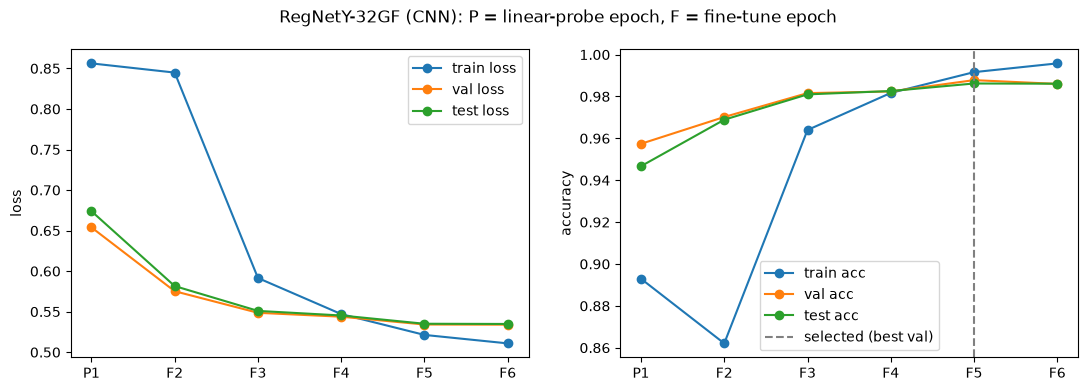

In [7]:
steps = range(1, len(history["test_acc"]) + 1)
labels = [f"{s[0].upper()}{i}" for i, s in enumerate(history["stage"], 1)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(steps, history["train_loss"], "o-", label="train loss")
ax1.plot(steps, history["val_loss"], "o-", label="val loss")
ax1.plot(steps, history["test_loss"], "o-", label="test loss")
ax1.set_xticks(list(steps), labels); ax1.set_ylabel("loss"); ax1.legend()
ax2.plot(steps, history["train_acc"], "o-", label="train acc")
ax2.plot(steps, history["val_acc"], "o-", label="val acc")
ax2.plot(steps, history["test_acc"], "o-", label="test acc")
ax2.axvline(best_step, color="gray", ls="--", label="selected (best val)")
ax2.set_xticks(list(steps), labels); ax2.set_ylabel("accuracy"); ax2.legend()
fig.suptitle("RegNetY-32GF (CNN): P = linear-probe epoch, F = fine-tune epoch")
plt.show()

# **Final Results**

In [8]:
model.load_state_dict(best_state)                    # weights of the epoch with the best validation accuracy
va_loss, va_acc, val_logits, val_labels = evaluate(model, val_loader, tta=True, return_logits=True)
_, acc_plain = evaluate(model, test_loader, tta=False)
te_loss, acc_tta, test_logits, test_labels = evaluate(model, test_loader, tta=True, return_logits=True)
print(f"Selected epoch: {history['stage'][best_step - 1]} {best_step} (best validation accuracy {va_acc:.4f})")
print(f"Final train loss {history['train_loss'][best_step - 1]:.4f} | test loss {te_loss:.4f}")
print(f"Test accuracy without TTA: {acc_plain:.4f}")
print(f"Test accuracy with flip TTA: {acc_tta:.4f}  ({int(round((1 - acc_tta) * len(test_dataset)))} errors out of {len(test_dataset)})")

preds = test_logits.argmax(1)
for c, name in enumerate(classes):
    mask = test_labels == c
    print(f"{name:>10}: {(preds[mask] == c).float().mean().item():.4f}")

torch.save({"val_logits": val_logits, "val_labels": val_labels, "test_logits": test_logits,
            "test_labels": test_labels, "val_idx": val_idx}, "logits_run9.pt")
torch.save(model.state_dict(), "regnety32gf_lpft_cifar10.pth")
print("saved", "logits_run9.pt", "and", "regnety32gf_lpft_cifar10.pth")

Selected epoch: finetune 5 (best validation accuracy 0.9878)
Final train loss 0.5213 | test loss 0.5351
Test accuracy without TTA: 0.9843
Test accuracy with flip TTA: 0.9862  (138 errors out of 10000)
  airplane: 0.9990
automobile: 0.9900
      bird: 0.9850
       cat: 0.9640
      deer: 0.9890
       dog: 0.9770
      frog: 0.9960
     horse: 0.9920
      ship: 0.9880
     truck: 0.9820
saved logits_run9.pt and regnety32gf_lpft_cifar10.pth
